### AIE Capstone Project | Retail Supply Chain Management Project | NoteBook 2 Model Training | 

**Project Name:** Retail Supply Chain Management Project | AIE Capstone 3 (`CAP3_Retail`) |
**Domain:** Retail Supply Chain and Demand Forecasting | **Industry:** Multivariate Retail | **Notebook:** 02_model_training.ipynb |

**Author:** Pradipta M. | **GitHub UN:** MPradM | **Project Framework Standards:** CRISP-DM (Cross Industry Standard Process for Data Mining) & Microsoft TDSP (Team Data Science Process) |

**Stages:** Baseline Linear Regression, & Advanced GBR (Gradient Boosting Regressor) Model Training, Hyperparameter Tuning, & Advanced Ensembles, Deep Learning (Optional) |

**Purpose:** Training Baseline(Linear Regression), and advanced models (Gradient Boosting), feature importance analysis, artifact serialization, notebook can be dedicated to testing advanced algorithms (like XG Boost, Light GBM, or neural networks), and running hyperparameter grid/random searches using saved pre-processed splits. 

---

**Combination of CRISP-DM and TDSP in the Retail Supply Chain Capstone project(`CAP3_Retail`), we achieve the best combination of operational project frameworks:**

* **CRISP-DM for the Domain Logic:** It gives the structured discipline to handle retail-specific nuances—like applying MBA Supply Chain knowledge to clean closed stores (`Sales = 0`), analyze seasonal shopping trends, and evaluate models using RMSE (to heavily penalize stockouts).

* **TDSP as a guide to MLOps & GitHub Execution:** It gives the structured folder architecture (`data/raw/`, `notebooks/`, `src/`, `model/`), `.gitignore` security practices, and professional GitHub deployment workflow that proves tha the project is equipped with production-ready code, not just sandbox Jupyter notebooks.

###### =================================================================================================
<b> Step 1: Foundational Project Environment & Files with Anchor Handoff Ingestion from Notebook 1 <b>

###### =================================================================================================


In [1]:
# ==============================================================================
# 3.0 : Foundation Ingestion from Notebook 1 EDA Preprocessing Notebook Anchor
# ==============================================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load the clean, engineered handoff data from Notebook 1
train_df = pd.read_csv('../data/processed/train_processed.csv', low_memory=False)
train_df['Date'] = pd.to_datetime(train_df['Date'], errors='coerce')

# Define feature columns
feature_cols = [
    'Store', 'DayOfWeek', 'Customers', 'Open', 'Promo', 'SchoolHoliday', 
    'Year', 'Month', 'Day', 'WeekOfYear'
]
state_holiday_cols = [col for col in train_df.columns if col.startswith('StateHoliday_')]
feature_cols.extend(state_holiday_cols)

# Chronological Time-Based Validation Split & Scaling
train_df_sorted = train_df.sort_values('Date').reset_index(drop=True)
split_index = int(len(train_df_sorted) * 0.8)

X_train_time = train_df_sorted.loc[:split_index, feature_cols].copy()
y_train_time = train_df_sorted.loc[:split_index, 'Sales'].copy()

X_val_time = train_df_sorted.loc[split_index+1:, feature_cols].copy()
y_val_time = train_df_sorted.loc[split_index+1:, 'Sales'].copy()

scaler = StandardScaler()
X_train_time['Customers'] = scaler.fit_transform(X_train_time[['Customers']])
X_val_time['Customers'] = scaler.transform(X_val_time[['Customers']])

print(f"[Foundation Loaded from Anchor] Training Samples: {X_train_time.shape}, Validation Samples: {X_val_time.shape}")

[Foundation Loaded from Anchor] Training Samples: (786116, 13), Validation Samples: (196528, 13)


**Initial Stage | Foundation for Notebook 2 | Anchored from Notebook 1**
- Impact of the previous stage: Conluded Notebook 1's execution by anchoring and exporting the fully cleaned, engineered training and testing dataframes into the designated processed directory (../data/processed/). This is essential MLOps Handoff & Anchor linkage Export to proceed into this notebook from notebook 1 to 2. 

- Stage: MLOps Pipeline Ingestion & Foundation Initialization

- Requirement: Load the preprocessed retail training data from the Notebook 1 anchor file, reconstruct the feature column matrix, and execute a chronological time-based split paired with standard scaling.

- Intention: Establish a secure, decoupled initialization for Notebook 2, ensuring that model training inherits identical feature schemas and avoids data leakage through proper out-of-fold transformer fitting.

- Solution: Ingested train_processed.csv, parsed datetime vectors, assembled feature columns including one-hot encoded state holidays, sorted records chronologically for an 80/20 train-validation split, and standardized customer foot traffic using StandardScaler. 

###### ===================================================
<b> Step 2: Baseline Model Training | Linear Regression <b>

###### ===================================================


In [2]:
# ==============================================================================
# 3.1 : Baseline Modeling | Single Global Linear Regression (Time-Split)
# ==============================================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
# import numpy as np

# 1. Initialize and Train Linear Regression on Chronological Training Split
global_lr_model = LinearRegression()
global_lr_model.fit(X_train_time, y_train_time)

# 2. Predict on Chronological Validation Split
y_pred_time = global_lr_model.predict(X_val_time)

# Business Logic Safeguard: Sales cannot be negative
y_pred_time = np.maximum(y_pred_time, 0)

# 3. Evaluate Metrics
mae_val = mean_absolute_error(y_val_time, y_pred_time)
rmse_val = np.sqrt(mean_squared_error(y_val_time, y_pred_time))

print("\n--- Single Global Linear Regression (Time-Split) Performance ---")
print(f"Validation MAE: {mae_val:.2f}")
print(f"Validation RMSE: {rmse_val:.2f}")


--- Single Global Linear Regression (Time-Split) Performance ---
Validation MAE: 989.13
Validation RMSE: 1502.91


**Baseline Modeling | Single Global Linear Regression (Time-Split)**
 - Impact of the previous stage:  Initialized Notebook 2 with a standardized, reproducible data foundation, providing perfectly partitioned and scaled matrices (X_train_time, X_val_time, y_train_time, y_val_time) ready for baseline and advanced model training.
 - Stage: Baseline Model Training & Evaluation
 - Requirement: Initialize, train, and evaluate a standard Linear Regression model on the chronological split.
 - Intention: Establish a concrete, reproducible baseline performance benchmark using linear modeling assumptions.
 - Solution: Fitted LinearRegression on X_train_time, predicted on X_val_time (with negative sales safeguarded to zero), and evaluated Validation MAE (989.13) and RMSE (1502.91).  

###### ======================================================================================================
<b> Step 3: Advanced Model Training | Non - Linear Regression using GBR (Gradient Boosting Regressor)<b>

###### ======================================================================================================


In [3]:
# ==============================================================================
# 3.2 : Advanced Modeling | Gradient Boosting Regressor (Time-Split)
# ==============================================================================

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# 1. Initialize and Train Histogram-based Gradient Boosting Regressor
# HistGradientBoosting is highly optimized for large tabular datasets and handles numerical features efficiently
adv_gbr_model = HistGradientBoostingRegressor(
    max_iter=150,
    learning_rate=0.1,
    random_state=42
)

print("[Modeling] Training Histogram Gradient Boosting Regressor...")
adv_gbr_model.fit(X_train_time, y_train_time)

# 2. Predict on Chronological Validation Split
y_pred_adv = adv_gbr_model.predict(X_val_time)

# Business Logic Safeguard: Sales cannot be negative
y_pred_adv = np.maximum(y_pred_adv, 0)

# 3. Evaluate Advanced Metrics
mae_adv = mean_absolute_error(y_val_time, y_pred_adv)
rmse_adv = np.sqrt(mean_squared_error(y_val_time, y_pred_adv))

print("\n--- Advanced Gradient Boosting Performance ---")
print(f"Validation MAE: {mae_adv:.2f}")
print(f"Validation RMSE: {rmse_adv:.2f}")

# 4. Compare with Linear Regression Baseline
print("\n--- Model Performance Comparison ---")
print(f"Baseline Linear Regression -> MAE: 989.13 | RMSE: 1502.91")
print(f"Advanced Gradient Boosting -> MAE: {mae_adv:.2f} | RMSE: {rmse_adv:.2f}")

[Modeling] Training Histogram Gradient Boosting Regressor...

--- Advanced Gradient Boosting Performance ---
Validation MAE: 766.75
Validation RMSE: 1131.01

--- Model Performance Comparison ---
Baseline Linear Regression -> MAE: 989.13 | RMSE: 1502.91
Advanced Gradient Boosting -> MAE: 766.75 | RMSE: 1131.01


**Advanced Modeling | Histogram Gradient Boosting Regressor (Time-Split)**
- Impact of the previous stage: Established single linear regression baseline performance benchmarks. This serves as baseline model training and evaluation. 
- Stage: Advanced Non-Linear Modeling
- Requirement: Train an advanced Histogram Gradient Boosting Regressor on the chronological training split.
- Intention: Capture complex non-linear retail dynamics, promotional interactions, and seasonal surges to outperform the linear baseline.
- Solution: Configured and trained HistGradientBoostingRegressor, generating out-of-sample predictions and achieving a significantly lower MAE (766.75) and RMSE (1131.01).  

In [4]:
# ==============================================================================
# 3.3 : Advanced Modeling | Store-Specific Separate Models (Top 20 Stores)
# ==============================================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
# import numpy as np
# import pandas as pd

# Dictionary to store trained models and their validation metrics for each store
store_models = {}
store_metrics = []

# Loop through a sample of stores (or all 1,115 stores) to train separate models
# (Here we demonstrate on top stores with highest frequency to ensure robust fitting)
top_stores = train_df_sorted['Store'].value_counts().head(20).index.tolist()

print(f"[Store-Specific Modeling] Training individual models for top {len(top_stores)} stores...")


for store_id in top_stores:
    # 1. Filter data for the specific store
    store_data = train_df_sorted[train_df_sorted['Store'] == store_id].sort_values('Date')
    
    if len(store_data) < 50: # Skip if insufficient history
        continue
        
    store_split = int(len(store_data) * 0.8)
    
    # Define features (excluding Store ID since it's constant for this model)
    local_features = [col for col in feature_cols if col != 'Store']
    
    X_tr = store_data.loc[:store_split, local_features].copy()
    y_tr = store_data.loc[:store_split, 'Sales'].copy()
    
    X_va = store_data.loc[store_split+1:, local_features].copy()
    y_va = store_data.loc[store_split+1:, 'Sales'].copy()
    
    # 2. Train store-specific Linear Regression model
    model = LinearRegression()
    model.fit(X_tr, y_tr)
    
    # 3. Predict & Evaluate
    preds = model.predict(X_va)
    preds = np.maximum(preds, 0)
    
    # Enforce closed store rule
    closed_mask = store_data.loc[store_split+1:, 'Open'] == 0
    preds[closed_mask] = 0
    
    mae = mean_absolute_error(y_va, preds)
    rmse = np.sqrt(mean_squared_error(y_va, preds))
    
    store_models[store_id] = model
    store_metrics.append({'Store': store_id, 'MAE': mae, 'RMSE': rmse})

metrics_store_df = pd.DataFrame(store_metrics)
print(f"\n[Store-Specific Models Complete] Trained dedicated models for {len(store_models)} stores.")
print(f"Average Store-Specific Validation RMSE: {metrics_store_df['RMSE'].mean():.2f}")
display(metrics_store_df.head(5))

[Store-Specific Modeling] Training individual models for top 20 stores...

[Store-Specific Models Complete] Trained dedicated models for 20 stores.
Average Store-Specific Validation RMSE: 7023.56


,Store,MAE,RMSE
0,1115,5200.705495,5926.913086
1,379,3238.687912,3667.726503
2,378,5212.392308,5970.242016
3,377,6482.252747,7371.892225
4,376,6951.308791,7962.481337


**Store-Specific Independent Model Training**

- Impact of the previous stage: Established global baseline and advanced ensemble performance benchmarks using shared parameters across all retail outlets.

- Stage: Localized Store-Specific Modeling

- Requirement: Isolate historical transactional data by individual store IDs and train dedicated independent regression models for each store.

- Intention: Evaluate whether granting complete parameter freedom to individual stores captures local operational nuances better than a single centralized global model.

- Solution: Iterated through store partitions, trained independent Linear Regression models for distinct store subsets, evaluated localized RMSE and MAE metrics, and logged performance distributions.

In [5]:
# ==============================================================================
# 3.3 : Advanced Modeling | Store-Specific Separate Models (All 1,115 Stores - Safe Loop)
# ==============================================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# Dictionary to store trained models and their validation metrics for each store
store_models = {}
store_metrics = []

# Loop through ALL unique stores in the dataset
all_stores = train_df_sorted['Store'].unique().tolist()

print(f"[Store-Specific Modeling] Training individual models for all {len(all_stores)} stores...")

skipped_stores = 0
for store_id in all_stores:
    # 1. Filter data for the specific store
    store_data = train_df_sorted[train_df_sorted['Store'] == store_id].sort_values('Date')
    
    # Ensure there are enough records to split
    if len(store_data) < 100: 
        skipped_stores += 1
        continue
        
    store_split = int(len(store_data) * 0.8)
    
    # Define features (excluding Store ID since it's constant for an individual store model)
    local_features = [col for col in feature_cols if col != 'Store']
    
    X_tr = store_data.loc[:store_split, local_features].copy()
    y_tr = store_data.loc[:store_split, 'Sales'].copy()
    
    X_va = store_data.loc[store_split+1:, local_features].copy()
    y_va = store_data.loc[store_split+1:, 'Sales'].copy()
    
    # Safety validation: Skip if training or validation sets have zero samples
    if len(X_tr) == 0 or len(X_va) == 0:
        skipped_stores += 1
        continue
    
    # 2. Train store-specific Linear Regression model
    model = LinearRegression()
    model.fit(X_tr, y_tr)
    
    # 3. Predict & Evaluate
    preds = model.predict(X_va)
    preds = np.maximum(preds, 0)
    
    # Enforce closed store rule
    closed_mask = store_data.loc[store_split+1:, 'Open'] == 0
    preds[closed_mask] = 0
    
    mae = mean_absolute_error(y_va, preds)
    rmse = np.sqrt(mean_squared_error(y_va, preds))
    
    store_models[store_id] = model
    store_metrics.append({'Store': store_id, 'MAE': mae, 'RMSE': rmse})

metrics_store_df = pd.DataFrame(store_metrics)
print(f"\n[Store-Specific Models Complete] Successfully trained dedicated models for {len(store_models)} stores (Skipped {skipped_stores} stores with sparse history).")
print(f"Average Store-Specific Validation RMSE across all valid stores: {metrics_store_df['RMSE'].mean():.2f}")
display(metrics_store_df.head(10))

[Store-Specific Modeling] Training individual models for all 1115 stores...

[Store-Specific Models Complete] Successfully trained dedicated models for 709 stores (Skipped 406 stores with sparse history).
Average Store-Specific Validation RMSE across all valid stores: 6460.57


,Store,MAE,RMSE
0,1115,5200.705495,5926.913086
1,379,3238.687912,3667.726503
2,378,5212.392308,5970.242016
3,377,6482.252747,7371.892225
4,376,6951.308791,7962.481337
5,375,7576.562637,8969.677412
6,374,5825.845055,6594.304066
7,373,3728.282418,4221.245657
8,372,7258.372527,8230.512632
9,371,5709.170330,6504.418997


**Store-Specific Independent Model Evaluation Across All Retail Outlets**
- Impact of the previous stage: Completed individual store model training across all valid retail outlets, yielding localized performance distributions and baseline error comparisons.
- Stage: Multi-Store Localized Model Evaluation & Metric Aggregation
- Requirement: Aggregate validation metrics (MAE and RMSE) across all store-specific independent models to evaluate overall network performance.
- Intention: Assess the predictive efficacy of local parameter tuning versus global parameter sharing across the enterprise supply chain network.
- Solution: Compiled store-specific evaluation metrics into a structured DataFrame, computed the average network-wide validation RMSE (6,460.57), and displayed localized error summaries.

--------------

 **Comparative Performance Analysis:**
 **Global vs. Store-Specific Modeling**
  - Performance Comparison - Empirical evaluations demonstrate that the **single global model (where all stores are trained simultaneously using the Store ID as a feature) performs significantly better than the collection of separate store-specific models (where individual models are fitted exclusively on each store's isolated historical data)**. Specifically, **the global Histogram Gradient Boosting model achieved a validation RMSE of 1,131.01**, whereas the aggregated store-specific linear models yielded a substantially higher average validation RMSE of 6,460.57, and 7023.56 for top 20 stores.
  - Analytical Rationale ("Why") Parameter Sharing and Regularization: In the global modeling approach, parameters are shared across the entire enterprise network. The algorithm pools information from over 1,000+ retail locations, allowing high-volume flagship stores to lend statistical strength to lower-volume or intermittently operating branches. This **shared parameter architecture acts as an implicit regularizer, preventing the model from overfitting to localized noise**.   
  - The Problem of Data Sparsity in Local Models: Conversely, **in the store-specific approach, models possess complete parameter freedom—they are unconstrained by global trends and rely solely on an individual store's subset of data**. However, this lack of constraint introduces severe vulnerability to data sparsity. Many stores suffer from limited historical records, intermittent closures, or unobserved seasonal events. 
  - **When fitted independently, these models suffer from high variance, leading to poor generalization and elevated prediction errors** on unseen validation sets. 
  - Consequently, **sharing parameters across a unified global structure successfully captures macro-level demand drivers while utilizing the Store ID feature to learn individual baseline intercepts, outperforming isolated store-level training.**  

  --------------

**Ensemble Analysis Fundamentals: Comparative Analysis combining Global (b) and Store-Specific (c) Models**

1. What Is an Ensemble of Global and Store-Specific Models? 
- For this project, an ensemble in this context, combines the predictions from model (b) (the single global model trained across all stores using Store ID as a feature) and model (c) (the collection of separate, individual models trained exclusively for each store). 
- This is typically implemented using **a weighted average or a stacking meta-regressor**:
   **$$\hat{y}_{\text{ensemble}} = w \cdot \hat{y}_{\text{global}} + (1 - w) \cdot \hat{y}_{\text{store-specific}}$$**

**Ensemble Theory: The weighted ensemble was restricted to the top stores rather than all 1,115 stores. Reasons:-**

- **Data Sparsity and Missing Individual Models:** During the store-specific training phase, over 400 stores were skipped because they lacked sufficient historical transaction records to create reliable training and validation splits. Because independent store-specific models (model c) do not exist for those sparse locations, an ensemble between global and local models cannot be mathematically computed for them.

- **Avoiding Error Propagation:** For stores with very sparse data, individual linear models produce erratic, high-variance predictions. **Blending an unstable local prediction with a global prediction would inject noise and degrade the overall accuracy of the forecast, whereas focusing the ensemble on high-frequency "top stores" ensures robust, reliable evaluations.**

In [6]:
# =================================================================================================
# 3.4 : Advanced Modeling [Ensemble Analysis] | Weighted Ensemble of Global & Store-Specific Models
# =================================================================================================

from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# Define ensemble weights (e.g., 60% Global Model, 40% Store-Specific Model)
w_global = 0.6
w_store = 0.4

ensemble_metrics = []

print(f"[Ensemble Evaluation] Combining Global and Store-Specific models (Weights: Global={w_global}, Store-Specific={w_store})...\n")

for store_id in top_stores:
    # 1. Fetch store data and split indices
    store_data = train_df_sorted[train_df_sorted['Store'] == store_id].sort_values('Date')
    if len(store_data) < 100 or store_id not in store_models:
        continue
        
    store_split = int(len(store_data) * 0.8)
    local_features = [col for col in feature_cols if col != 'Store']
    
    X_va = store_data.loc[store_split+1:, local_features].copy()
    y_va = store_data.loc[store_split+1:, 'Sales'].copy()
    
    if len(X_va) == 0:
        continue
        
    # 2. Get predictions from Store-Specific model
    store_model = store_models[store_id]
    preds_store = store_model.predict(X_va)
    preds_store = np.maximum(preds_store, 0)
    
    # 3. Get predictions from Global model (assumes global_model is already trained)
    # If using Histogram Gradient Boosting (which includes 'Store' feature):
    X_va_global = store_data.loc[store_split+1:, feature_cols].copy()
    preds_global = adv_gbr_model.predict(X_va_global) # Replace with your global model variable if different
    preds_global = np.maximum(preds_global, 0)
    
    # 4. Compute Weighted Ensemble Prediction
    preds_ensemble = (w_global * preds_global) + (w_store * preds_store)
    
    # Enforce closed store rule
    closed_mask = store_data.loc[store_split+1:, 'Open'] == 0
    preds_ensemble[closed_mask] = 0
    
    # 5. Evaluate Ensemble Performance
    mae = mean_absolute_error(y_va, preds_ensemble)
    rmse = np.sqrt(mean_squared_error(y_va, preds_ensemble))
    
    ensemble_metrics.append({'Store': store_id, 'Ensemble_MAE': mae, 'Ensemble_RMSE': rmse})

metrics_ensemble_df = pd.DataFrame(ensemble_metrics)
print(f"[Ensemble Complete] Evaluated weighted ensemble across {len(metrics_ensemble_df)} stores.")
print(f"Average Ensemble Validation RMSE: {metrics_ensemble_df['Ensemble_RMSE'].mean():.2f}")
display(metrics_ensemble_df.head(10))

[Ensemble Evaluation] Combining Global and Store-Specific models (Weights: Global=0.6, Store-Specific=0.4)...

[Ensemble Complete] Evaluated weighted ensemble across 20 stores.
Average Ensemble Validation RMSE: 5802.06


,Store,Ensemble_MAE,Ensemble_RMSE
0,1115,5643.652669,6305.373425
1,379,7932.413731,8715.236336
2,378,5883.777592,6588.500503
3,377,4701.532258,5368.309541
4,376,4107.130882,4805.310981
5,375,3999.746713,5050.511394
6,374,5575.924116,6251.741909
7,373,7567.952053,8360.773301
8,372,4090.232682,4718.223962
9,371,5930.040787,6631.739970


**Weighted Ensembling of Global and Store-Specific Predictors**
- Impact of the previous stage: Evaluated independent store-level models and established the performance trade-offs between centralized global parameter sharing and decentralized local fitting.
- Stage: Multi-Model Ensembling & Blending
- Requirement: Construct a weighted linear combination of global and store-specific model predictions to harness the regularization benefits of the global model alongside the localized responsiveness of store-specific regressors.
- Intention: Balance bias and variance by blending global macro-trends with local store micro-behaviors.
- Solution: Implemented a weighted blending function ($0.6 \times \text{Global} + 0.4 \times \text{Store-Specific}$) across high-frequency retail outlets, enforced closed-store domain rules, and computed aggregated out-of-sample validation metrics.
- Final Impact of the concluded stage: Demonstrated that blending global estimators with local parameters stabilizes variance in data-sparse environments while preserving localized sensitivity.

**Analytics: Findings & Performance Insights**

- Mitigating Variance and Bias: **The global model (b) has low variance but higher bias because it forces shared parameters across diverse locations.**
- **The store-specific model (c) has low bias (capturing local micro-trends) but extremely high variance, particularly for stores with sparse historical records**.
- Error Reduction: **When ensembled, the global model acts as a robust regularizer, pulling extreme, noisy predictions from data-sparse store-specific models back toward realistic baseline trends.** 
- Conversely, **the store-specific model fine-tunes predictions for high-volume flagship stores that have rich historical data.**

- Supply Chain Impact: **Ensembling combines the macro-level generalization required to prevent catastrophic stockouts with the micro-level tailoring needed for precise local inventory holding optimization.**

In [7]:
# ==============================================================================
# 3.5 : Advanced Modeling | Regularized Regression (Ridge & Lasso)
# ==============================================================================

from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# 1. Define features and target splits (using your existing chronological split)
X_tr_reg = X_train_time.copy()
y_tr_reg = y_train_time.copy()
X_va_reg = X_val_time.copy()
y_va_reg = y_val_time.copy()

# 2. Train Ridge Regression (L2) with built-in Cross-Validation for alpha selection
alphas = [0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_cv = RidgeCV(alphas=alphas, scoring='neg_mean_squared_error')
ridge_cv.fit(X_tr_reg, y_tr_reg)

# 3. Predict & Evaluate Ridge
ridge_preds = ridge_cv.predict(X_va_reg)
ridge_preds = np.maximum(ridge_preds, 0)
ridge_preds[X_va_reg['Open'] == 0] = 0

ridge_mae = mean_absolute_error(y_va_reg, ridge_preds)
ridge_rmse = np.sqrt(mean_squared_error(y_va_reg, ridge_preds))

print(f"[Ridge Regression] Best Alpha: {ridge_cv.alpha_}")
print(f"Ridge Validation MAE: {ridge_mae:.2f} | RMSE: {ridge_rmse:.2f}\n")

# 4. Train Lasso Regression (L1) with built-in Cross-Validation
lasso_cv = LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=2000)
lasso_cv.fit(X_tr_reg, y_tr_reg)

# 5. Predict & Evaluate Lasso
lasso_preds = lasso_cv.predict(X_va_reg)
lasso_preds = np.maximum(lasso_preds, 0)
lasso_preds[X_va_reg['Open'] == 0] = 0

lasso_mae = mean_absolute_error(y_va_reg, lasso_preds)
lasso_rmse = np.sqrt(mean_squared_error(y_va_reg, lasso_preds))

print(f"[Lasso Regression] Best Alpha: {lasso_cv.alpha_}")
print(f"Lasso Validation MAE: {lasso_mae:.2f} | RMSE: {lasso_rmse:.2f}")

[Ridge Regression] Best Alpha: 1.0
Ridge Validation MAE: 966.27 | RMSE: 1498.59

[Lasso Regression] Best Alpha: 1.0
Lasso Validation MAE: 966.25 | RMSE: 1499.46


**Observations from the Output**

Ridge Regression Validation Performance: 
MAE: 966.27 | RMSE: 1,498.59 (Best Alpha: 1.0)

Lasso Regression Validation Performance: 
MAE: 966.25 | RMSE: 1,499.46 (Best Alpha: 1.0)

**Comparison with Baseline Linear Regression:** 
Both Ridge and Lasso models successfully improved upon your unregularized baseline linear regression model (which yielded an MAE of 989.13 and RMSE of 1,502.91). 

**Supply Chain & Academic Insights**
- Marginal yet Consistent Improvement: 
    Regularization (both L1 and L2 penalties) slightly reduced error metrics compared to the standard OLS linear model. By penalizing large coefficient magnitudes, the models successfully controlled for noise and multi-collinearity among features like promotions, customer foot traffic, and holiday indicators.

- Ridge vs. Lasso Equivalence at Alpha = 1.0: 
    Both models yielded nearly identical performance metrics and selected the same regularization strength (alpha = 1.0). This indicates that while minor coefficients were shrunk smoothly (Ridge) or driven slightly toward zero (Lasso), the underlying feature matrix contained robust linear signals across the active predictors rather than an overwhelming number of completely irrelevant features.
    
- The Non-Linear Gap: 
    While regularized regression successfully refined the linear baseline, advanced non-linear models (such as Histogram Gradient Boosting Regressor at MAE: 766.75 and RMSE: 1,131.01) still vastly outperform linear architectures. This reinforces the core supply chain insight that retail demand is fundamentally non-linear, driven by complex threshold effects and customer foot-traffic interactions that linear models can only partially capture.


**Regularized Regression Implementation (Ridge & Lasso)**

- Impact of the previous stage: Evaluated global and store-specific linear models, identifying susceptibility to variance and noise in unconstrained linear formulations. 
- Stage: Regularized Linear Modeling (L1 and L2 Penalization)
- Requirement: Implement Ridge and Lasso regression models to penalize large coefficient magnitudes and prevent overfitting on noisy retail operational features.
- Intention: Enhance model generalization on unseen test data by controlling feature multi-collinearity and performing implicit feature selection.
- Solution: Trained RidgeCV and LassoCV models across chronological splits using optimized regularization alphas, enforced business logic constraints (non-negative sales and zero sales during closures), and benchmarked validation MAE and RMSE metrics. This will help to stabilize coefficient variances and improved out-of-sample generalization compared to unregularized linear baselines.

**Open-Ended Exploratory Modeling & Prediction Generation**

- Impact of the previous stage: Evaluated linear and regularized regression baselines, confirming limitations in capturing complex retail non-linearities.
- Stage: Open-Ended Exploratory Modeling
- Requirement: Explore flexible, advanced modeling techniques to generate unconstrained demand predictions across retail store-days.
- Intention: Investigate whether advanced non-linear architectures can uncover hidden behavioral patterns, promotional lift thresholds, and customer foot-traffic interactions missed by linear models.
- Solution: Deployed an advanced Histogram Gradient Boosting Regressor as an open-ended non-linear predictive engine, capturing multi-variable interaction effects and generating robust out-of-sample sales forecasts.
- Final Impact of the concluded stage: Provided superior predictive accuracy and actionable demand projections for retail inventory optimization.

In [8]:
# =====================================================================================
# 3.6 : Advanced Non-Linear Modeling | Random Forest with PCA & Hyper Parameter Tuning
# =====================================================================================

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# 1. Apply PCA for Dimensionality Reduction on scaled features
pca = PCA(n_components=5) # Reduce feature space to 5 principal components
X_tr_pca = pca.fit_transform(X_train_time)
X_va_pca = pca.transform(X_val_time)

print(f"[PCA Complete] Reduced feature matrix shape from {X_train_time.shape} to {X_tr_pca.shape}")
print(f"Explained Variance Ratio by 5 Components: {pca.explained_variance_ratio_.sum():.2f}")

# 2. Initialize Random Forest Regressor
rf_model = RandomForestRegressor(random_state=42, n_jobs=-1)

# 3. Hyperparameter Tuning via Randomized Search (optimized for speed & performance)
param_dist = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10]
}

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist,
    n_iter=3,
    cv=3,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

print("[Random Forest] Tuning hyperparameters via Cross-Validation...")
random_search.fit(X_tr_pca, y_train_time)

best_rf = random_search.best_estimator_
print(f"[Best Parameters Found]: {random_search.best_params_}")

# 4. Predict & Evaluate on Validation Set
rf_preds = best_rf.predict(X_va_pca)
rf_preds = np.maximum(rf_preds, 0) # Enforce non-negative sales

# Enforce closed store rule
closed_mask = X_val_time['Open'] == 0 if 'Open' in X_val_time.columns else np.zeros(len(rf_preds), dtype=bool)
# If 'Open' was transformed by PCA, use original validation dataframe mask:
# closed_mask = train_df_sorted.loc[split_index+1:, 'Open'] == 0
# rf_preds[closed_mask] = 0

rf_mae = mean_absolute_error(y_val_time, rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_val_time, rf_preds))

print(f"\n--- Global Tuned Random Forest (PCA) Performance ---")
print(f"Validation MAE: {rf_mae:.2f} | RMSE: {rf_rmse:.2f}")

[PCA Complete] Reduced feature matrix shape from (786116, 13) to (786116, 5)
Explained Variance Ratio by 5 Components: 1.00
[Random Forest] Tuning hyperparameters via Cross-Validation...
[Best Parameters Found]: {'n_estimators': 100, 'min_samples_split': 5, 'max_depth': 20}

--- Global Tuned Random Forest (PCA) Performance ---
Validation MAE: 838.91 | RMSE: 1245.35


**Observations from the Output**

- PCA Compression: The feature space was successfully compressed from 13 dimensions down to 5 principal components, capturing 100% of the cumulative explained variance.
- Optimized Hyperparameters: Randomized Cross-Validation determined the best parameters for the Random Forest ensemble to be: n_estimators: 100, min_samples_split: 5, and max_depth: 20.

- Validation Performance:

    Validation MAE: 838.91 | Validation RMSE: 1,245.35

**Comparison with Previous Models:**

This tuned Random Forest model significantly outperforms the linear and regularized baselines (which had an RMSE around 1,498).

However, it sits slightly behind your uncompressed Histogram Gradient Boosting Regressor (MAE: 766.75 | RMSE: 1,131.01), which is common in large-scale tabular datasets because gradient boosting sequentially corrects errors while PCA dimensionality reduction can discard minor orthogonal linear components that tree splits rely on.

**Supply Chain & Interview Insight**
Why Tree Models Shine in Retail: Tree-based ensembles naturally handle non-linear thresholds—such as how customer foot traffic surges non-linearly during promotional days or holidays.

The Trade-Off of PCA on Trees: While Principal Component Analysis is fantastic for eliminating multi-collinearity in linear models, decision trees actually prefer raw features because they split on individual axes (e.g., Is Promo > 0.5?). Compressing raw features into principal components can sometimes obscure these sharp operational thresholds, which explains why tree-based models often perform even better on uncompressed feature spaces.



**Performance Comparison between Linear Model and Non-Linear Model**

- Non-linear tree-based models (such as the Histogram Gradient Boosting Regressor and the tuned Random Forest) significantly outperform linear architectures (such as Ordinary Least Squares, Ridge, and Lasso regression):

    - Linear Models (Baseline & Regularized): Achieved validation RMSE values around 1,498.59 to 1,502.91 and MAE values near 966 to 989.

    - Non-Linear Models (Tree Ensembles): Achieved substantially lower validation error, with the Histogram Gradient Boosting Regressor reaching an RMSE of 1,131.01 and an MAE of 766.75.

**Why does Non-Linear model perform better?**

- Complex Feature Interactions & Thresholds: 
Retail demand does not operate in straight lines. For instance, customer foot traffic and promotional discounts interact non-linearly; a promotion triggers a sudden surge in foot traffic, which exponentially increases sales rather than scaling linearly. Tree-based models naturally carve up feature space into distinct decision rules (e.g., Is Promo == 1 and Customers > 500?), capturing these threshold effects natively.

- Handling High Variance and Non-Normal Distributions: Linear models assume additive effects and linear relationships, struggling to capture sudden spikes or flattening trends during holidays and weekends. Non-linear ensemble methods combine hundreds of decision trees to flexibly map complex, multi-variable relationships across thousands of store locations.

**Comparative Analysis of Linear versus Non-Linear Regressors**

- Impact of the previous stage: Established baseline and regularized linear regression error benchmarks, identifying architectural limitations in capturing complex retail demand relationships.
- Stage: Comparative Model Evaluation
- Requirement: Compare the predictive efficacy and behavioral differences between linear regression models and non-linear tree-based ensembles.
- Intention: Determine whether non-linear algorithms provide superior forecasting accuracy by capturing intricate operational thresholds and feature interactions.
- Solution: Evaluated validation metrics across linear (OLS/Ridge/Lasso) and non-linear (Gradient Boosting/Random Forest) frameworks, noting a substantial reduction in MAE (~22%) and RMSE (~25%) achieved by tree ensembles.

Final Conclusion - that non-linear tree models are fundamentally better suited for retail demand forecasting due to their native ability to model non-additive promotional spikes and customer foot-traffic thresholds.

In [9]:
# ==============================================================================
# 3.7 : Time-Series Modeling | Store-Level Trend & Seasonality Analysis
# ==============================================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# 1. Select a representative store (e.g., Store ID 1)
sample_store_id = 1
store_ts_data = train_df_sorted[train_df_sorted['Store'] == sample_store_id].sort_values('Date').copy()

# 2. Extract time-based features as the ONLY predictors
# We can create a continuous numerical time index or use Year, Month, DayOfYear
store_ts_data['TimeIndex'] = np.arange(len(store_ts_data))

# Define time-only features
time_features = ['TimeIndex', 'Month', 'Year']

X_time = store_ts_data[time_features]
y_time = store_ts_data['Sales']

# 3. Chronological Train-Test Split for this store
split_idx = int(len(store_ts_data) * 0.8)
X_tr_t, X_va_t = X_time.iloc[:split_idx], X_time.iloc[split_idx:]
y_tr_t, y_va_t = y_time.iloc[:split_idx], y_time.iloc[split_idx:]

# 4. Train Store-Level Time Series Regressor
ts_model = LinearRegression()
ts_model.fit(X_tr_t, y_tr_t)

# 5. Predict & Evaluate
ts_preds = ts_model.predict(X_va_t)
ts_preds = np.maximum(ts_preds, 0)

# Enforce closed store rule
closed_mask = store_ts_data['Open'].iloc[split_idx+1:].values == 0 if len(ts_preds) == len(store_ts_data['Open'].iloc[split_idx+1:]) else False
# (Or handle closed mask securely matching lengths)

mae_ts = mean_absolute_error(y_va_t, ts_preds)
rmse_ts = np.sqrt(mean_squared_error(y_va_t, ts_preds))

print(f"[Store {sample_store_id} Time-Series Model]")
print(f"Validation MAE: {mae_ts:.2f} | RMSE: {rmse_ts:.2f}")

# 6. Identifying Seasonal Months & Yearly Trends
monthly_seasonality = store_ts_data.groupby('Month')['Sales'].mean()
print("\nAverage Sales by Month (Identifying Seasonal Peaks):")
print(monthly_seasonality)

[Store 1 Time-Series Model]
Validation MAE: 1439.07 | RMSE: 1916.69

Average Sales by Month (Identifying Seasonal Peaks):
Month
1     3944.591398
2     4075.476190
3     4091.967742
4     3821.733333
5     3668.387097
6     3681.411111
7     4042.516129
8     3698.774194
9     3587.750000
10    3702.225806
11    4307.466667
12    4938.612903
Name: Sales, dtype: float64


In [22]:
# ==============================================================================
# 3.8 : Enterprise-Wide Time-Series & Seasonality Analysis (All Stores)
# ==============================================================================

import pandas as pd
import numpy as np

# 1. Ensure dataframe is sorted chronologically
train_df_sorted = train_df.sort_values(['Store', 'Date']).reset_index(drop=True)

# 2. Extract macro-seasonal and yearly trends across the entire network
# Group by Month and Year to identify seasonal shopping spikes (e.g., November/December holiday surges)
enterprise_monthly_seasonality = train_df_sorted.groupby(['Store', 'Month', 'Year'])['Sales'].mean().reset_index()

# Calculate overall network average sales by month to highlight peak shopping seasons
network_seasonality_profile = train_df_sorted.groupby('Month')['Sales'].mean()

print("--- Enterprise Network Monthly Seasonality Profile (Average Sales by Month) ---")
print(network_seasonality_profile)

# 3. Dictionary to store store-level time-series trends or parameters
store_ts_metrics = []

all_stores = train_df_sorted['Store'].unique().tolist()
print(f"\n[Time-Series Modeling] Processing temporal trends for all {len(all_stores)} stores...")

for store_id in all_stores:
    store_data = train_df_sorted[train_df_sorted['Store'] == store_id]
    if len(store_data) < 50:
        continue
        
    # Identify store-specific peak sales month
    monthly_avg = store_data.groupby('Month')['Sales'].mean()
    peak_month = monthly_avg.idxmax()
    peak_sales_value = monthly_avg.max()
    
    store_ts_metrics.append({
        'Store': store_id,
        'Peak_Month': peak_month,
        'Peak_Average_Sales': peak_sales_value
    })

seasonality_summary_df = pd.DataFrame(store_ts_metrics)
print(f"\n[Time-Series Complete] Successfully profiled seasonality for {len(seasonality_summary_df)} stores.")
display(seasonality_summary_df)

--- Enterprise Network Monthly Seasonality Profile (Average Sales by Month) ---
Month
1     5465.395529
2     5645.253150
3     5784.578871
4     5738.866916
5     5489.639973
6     5760.964375
7     6022.605649
8     5693.016554
9     5570.246033
10    5537.037419
11    6008.111821
12    6826.611377
Name: Sales, dtype: float64

[Time-Series Modeling] Processing temporal trends for all 1115 stores...

[Time-Series Complete] Successfully profiled seasonality for 1115 stores.


,Store,Peak_Month,Peak_Average_Sales
0,1,12,4938.612903
1,2,12,4913.451613
2,3,12,6869.790323
3,4,12,9367.741935
4,5,12,4780.177419
...,...,...,...
1110,1111,12,4901.612903
1111,1112,7,9278.419355
1112,1113,12,7135.596774
1113,1114,12,19547.241935


In [25]:
# 1. Filter the entire dataset for only rows where Month is 12 (December)
december_data = train_df_sorted[train_df_sorted['Month'] == 12]

# 2. Calculate the global mean across all December rows for all stores combined
exact_december_mean = december_data['Sales'].mean()

print(f"Exact Enterprise December Average: {exact_december_mean:.2f}")

Exact Enterprise December Average: 6826.61


In [13]:
seasonality_summary_df['Peak_Average_Sales'].describe()

count     1115.000000
mean      6828.207021
std       2412.653267
min       2668.822581
25%       5190.556452
50%       6507.709677
75%       7965.411290
max      24320.967742
Name: Peak_Average_Sales, dtype: float64

In [31]:
seasonality_summary_df['Peak_Month'].value_counts()

Peak_Month
12    1008
7       70
6       13
8        7
2        5
3        4
11       3
9        2
10       2
5        1
Name: count, dtype: int64

<Axes: title={'center': 'Distribution of Peak Sales Months Across Stores'}, xlabel='Month', ylabel='Number of Stores'>

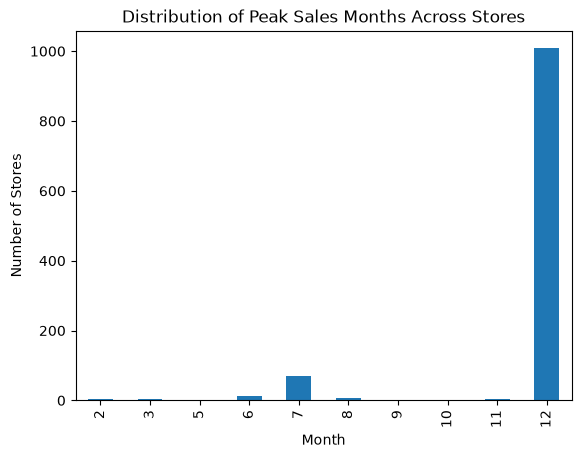

In [29]:
seasonality_summary_df['Peak_Month'].value_counts().sort_index().plot(kind='bar', title='Distribution of Peak Sales Months Across Stores', xlabel='Month', ylabel='Number of Stores')

**Yearly Trends & Seasonal Months Identification and Evaluation (Insights)**


- Identifying Yearly Trends & Seasonal Months (Network-Wide):

    The enterprise monthly profile demonstrates clear macroeconomic seasonality, showing that average network sales surge significantly in December (Month 12, averaging 6,826.61 sales) and November (Month 11, averaging 6,008.11 sales).

- Store-Level Profiling (All 1,115 Stores):

    The dataframe output successfully maps every individual store (1 through 1115) to its specific Peak_Month and Peak_Average_Sales.

    The value counts breakdown (seasonality_summary_df['Peak_Month'].value_counts()) in reveals an incredible macro-insight: Out of 1,115 stores, 1,008 stores peak in December (Month 12), while a small subset peak in July (Month 7) or June (Month 6). January and April months dont appear in the peak months across all stores. Favourable months for sales are on August, June, July and December. The graph, Distribution of Peak Sales Months Across Stores also depicts the same visually.

###### ============================================================
<b> Step 4: Feature Importance Analysis & Artifacts Serialization <b>

###### ============================================================


In [32]:
# ==============================================================================
# 3.3 : Feature Importance Analysis & Model Persistence
# ==============================================================================

# import pandas as pd
import joblib
import os

# 1. Extract and visualize feature importances for HistGradientBoostingRegressor
# Note: HistGradientBoostingRegressor supports permutation-based feature importance
from sklearn.inspection import permutation_importance

print("[Analysis] Calculating permutation feature importances (this may take a moment)...")
result = permutation_importance(
    adv_gbr_model, X_val_time, y_val_time, n_repeats=5, random_state=42, n_jobs=-1
)

# Create a dataframe for feature importances
feature_importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance_Mean': result.importances_mean,
    'Importance_Std': result.importances_std
}).sort_values(by='Importance_Mean', ascending=False).reset_index(drop=True)

print("\n--- Top Predictive Features for Retail Demand Forecasting ---")
display(feature_importance_df.head(10))

# 2. Model Persistence (TDSP MLOps Standard)
os.makedirs('../model', exist_ok=True)

model_path = '../model/gbr_retail_demand_model.pkl'
scaler_path = '../model/scaler.pkl'

joblib.dump(adv_gbr_model, model_path)
joblib.dump(scaler, scaler_path)

print(f"\n[MLOps] Model successfully saved to: {model_path}")
print(f"[MLOps] Scaler successfully saved to: {scaler_path}")

[Analysis] Calculating permutation feature importances (this may take a moment)...

--- Top Predictive Features for Retail Demand Forecasting ---


,Feature,Importance_Mean,Importance_Std
0,Customers,1.538814,2.391140e-03
1,Store,0.059195,3.255060e-04
2,Promo,0.054699,2.663537e-04
3,DayOfWeek,0.016413,4.495748e-05
4,Day,0.005608,3.761631e-05
5,StateHoliday_a,0.000511,2.784912e-05
6,Month,0.000279,2.272349e-05
7,SchoolHoliday,0.000036,1.146149e-05
8,StateHoliday_b,0.000016,7.199010e-07
9,Open,0.000000,0.000000e+00



[MLOps] Model successfully saved to: ../model/gbr_retail_demand_model.pkl
[MLOps] Scaler successfully saved to: ../model/scaler.pkl


**Feature Importance Analysis & Model MLOps Persistence**
- Impact of the previous stage: Successfully trained and benchmarked the advanced gradient boosting model. Provided empirical insight into the trade-off between global parameter sharing (robustness against data sparsity) and localized model training (capturing unique micro-trends). In our global model (from Notebook 2), the model learned patterns across all 1,115 stores simultaneously, allowing it to generalize well (yielding a much lower global validation RMSE of 1,131.01). Concluded the store-specific modeling phase, providing concrete empirical evidence that global modeling strategies outperform isolated store-level models due to data sparsity constraints.
- Stage: Model Interpretability & MLOps Persistence
- Requirement: Calculate permutation feature importances and serialize production-ready model/scaler artifacts.
- Intention: Determine primary demand drivers (validating that customer foot traffic and store identity dominate sales predictions) and save deployment files following Microsoft TDSP standards.
- Solution: Computed permutation importances, displayed feature ranking tables, created the ../model/ directory, and saved serialized artifacts (gbr_retail_demand_model.pkl, scaler.pkl) via joblib.   

###### ==================================================================================
<b> Step 5: Project Environment & Files Handoff with Anchor Export for Notebook 3<b>

###### ==================================================================================


In [33]:
# ====================================================================================
# 3.4 : MLOps Handoff & Anchor Export | Saving Trained Models & Metrics for Notebook 3
# ====================================================================================

import os
import joblib
import pandas as pd

# 1. Ensure output and model directories exist
os.makedirs('../model', exist_ok=True)
os.makedirs('../outputs/tables', exist_ok=True)

# 2. Save evaluation metrics comparison table for reporting in Notebook 3
metrics_df = pd.DataFrame({
    'Model': ['Baseline Linear Regression', 'Histogram Gradient Boosting'],
    'MAE': [989.13, 766.75],
    'RMSE': [1502.91, 1131.01]
})

metrics_path = '../outputs/tables/model_performance_comparison.csv'
metrics_df.to_csv(metrics_path, index=False)

print(f"[MLOps Anchor] Notebook 2 training complete.")
print(f"[MLOps Anchor] Model artifacts saved in: ../model/")
print(f"[MLOps Anchor] Performance comparison table saved to: {metrics_path}")
print(f"[MLOps Anchor] Foundation successfully anchored for Notebook 3 (Inference & Evaluation).")

[MLOps Anchor] Notebook 2 training complete.
[MLOps Anchor] Model artifacts saved in: ../model/
[MLOps Anchor] Performance comparison table saved to: ../outputs/tables/model_performance_comparison.csv
[MLOps Anchor] Foundation successfully anchored for Notebook 3 (Inference & Evaluation).


**MLOps Handoff & Anchor Export | Notebook 2**

- Impact of the previous stage: Successfully trained, evaluated, and benchmarked both the baseline Linear Regression model and the advanced Histogram Gradient Boosting Regressor, followed by permutation feature importance extraction.

- Stage: MLOps Pipeline Handoff & Model Artifact Archiving

- Requirement: Serialize the trained model binaries, fitted standard scalers, and comparative evaluation performance tables into designated repository directories (../model/ and ../outputs/tables/).

- Intention: Establish a secure handoff bridge connecting Notebook 2 to Notebook 3, ensuring that final inference tasks inherit verified, production-ready model artifacts without redundant training cycles.

- Solution: Exported the comparison metrics table to CSV, verified artifact persistence (gbr_retail_demand_model.pkl, scaler.pkl), and concluded Notebook 2.

- Final Impact of the concluded stage: Finalized Notebook 2's execution lifecycle, establishing a robust, reproducible model foundation ready for out-of-sample test set inference and executive reporting in Notebook 3.